# 04 · Semantic IDs with RQ-VAE

Milestone 4 of the hands-on track. TIGER (and PLUM after it) tokenizes items with an **RQ-VAE**: an MLP encoder compresses the text embedding to a small latent, a residual quantizer turns it into one code per level, and a decoder reconstructs the embedding. Unlike residual k-means (milestone 3), the latent space is *learned jointly* with the codebooks.

Setup (`src/genrec/tokenizers/rqvae.py`, `configs/rqvae_beauty.yaml`): 768 → 512 → 256 → 128 → 32 encoder, 3 levels × 256 codes, β = 0.25, inputs standardized per dimension, codebooks initialized with k-means, dead codes reset every 50 epochs until epoch 2000, 3000 epochs total.

Needs `python scripts/train_rqvae.py --config configs/rqvae_beauty.yaml` and the milestone 3 `python scripts/build_semantic_ids.py --method residual --k 256`.

In [1]:
import os
os.chdir('..')  # run from repo root

import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from genrec.data.amazon import load_processed
from genrec.data.sequences import leave_one_out
from genrec.embeddings.text import embeddings_path
from genrec.metrics import evaluate
from genrec.models.baselines import SemanticKNN
from genrec.tokenizers.kmeans import code_stats
from genrec.tokenizers.rqvae import fit_rqvae
from genrec.utils import load_config

sequences, items = load_processed('data/processed/beauty')
emb = np.load(embeddings_path('data/processed/beauty'))[1:]  # row i-1 = item i
train, valid, test = leave_one_out(sequences)
sid_dir = Path('data/processed/beauty/semantic_ids')

tokenizers = {'residual k-means 3x256': 'residual_kmeans-3x256', 'RQ-VAE 3x256': 'rqvae-3x256'}
codes = {t: np.load(sid_dir / f'{n}.npy')[1:, :3] for t, n in tokenizers.items()}  # drop padding row and suffix
quantized = {t: np.load(sid_dir / f'{n}_quantized.npy') for t, n in tokenizers.items()}
history = pd.DataFrame(json.loads((sid_dir / 'rqvae-3x256_history.json').read_text()))

def knn_valid(item_emb):
    """Validation NDCG@10 of semantic kNN (n_recent=5, decay=0.5) on the given item embeddings."""
    return evaluate(SemanticKNN(item_emb).recommend(valid[0], 10), valid[1], [10])['ndcg@10']

## Training curve

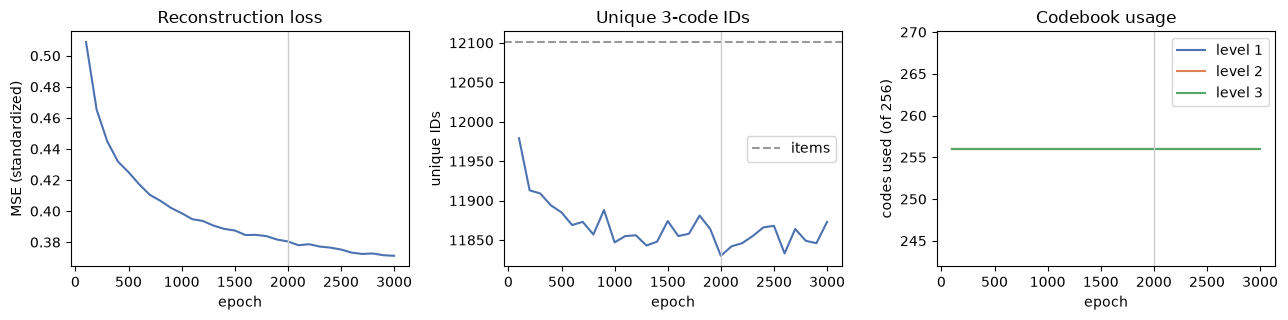

,epoch,recon_loss,q_loss,unique_ids,l1_used,l2_used,l3_used,reset
0,100,0.5088,0.1080,11979,256,256,256,1
4,500,0.4251,0.2776,11885,256,256,256,0
9,1000,0.3987,0.3467,11847,256,256,256,0
19,2000,0.3805,0.4181,11830,256,256,256,0
29,3000,0.3712,0.4657,11873,256,256,256,0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].plot(history.epoch, history.recon_loss, color='#4C72B0')
axes[0].set(xlabel='epoch', ylabel='MSE (standardized)', title='Reconstruction loss')
axes[1].plot(history.epoch, history.unique_ids, color='#4C72B0')
axes[1].axhline(len(emb), color='#999999', ls='--', label='items')
axes[1].set(xlabel='epoch', ylabel='unique IDs', title='Unique 3-code IDs')
axes[1].legend()
for level, color in zip([1, 2, 3], ['#4C72B0', '#DD8452', '#55A868']):
    axes[2].plot(history.epoch, history[f'l{level}_used'], color=color, label=f'level {level}')
axes[2].set(xlabel='epoch', ylabel='codes used (of 256)', title='Codebook usage')
axes[2].legend()
for ax in axes:
    ax.axvline(2000, color='#cccccc', lw=1)  # dead-code resets stop here
plt.tight_layout()
plt.show()
history.iloc[[0, 4, 9, 19, -1]].round(4)

## RQ-VAE vs. residual k-means
Same statistics as milestone 3. `recon_cosine` compares each item's embedding with the decoded embedding of its code tuple; `knn_ndcg@10` runs semantic kNN on those decoded embeddings.

In [3]:
rows = []
for t in tokenizers:
    stats = code_stats(codes[t], emb, quantized[t][1:])
    rows.append({'tokenizer': t, **stats, 'knn_ndcg@10': knn_valid(quantized[t])})
rows.append({'tokenizer': 'raw embeddings (no quantization)', 'knn_ndcg@10': knn_valid(np.vstack([np.zeros((1, emb.shape[1])), emb]))})
compare = pd.DataFrame(rows).set_index('tokenizer')
compare[['unique_ids', 'collision_rate', 'max_group', 'l1_perplexity', 'l2_perplexity', 'l3_perplexity',
         'recon_cosine', 'knn_ndcg@10']].round(4)

,unique_ids,collision_rate,max_group,l1_perplexity,l2_perplexity,l3_perplexity,recon_cosine,knn_ndcg@10
tokenizer,,,,,,,,
residual k-means 3x256,11354.0,0.1143,6.0,228.4421,126.6325,49.3053,0.9690,0.0157
RQ-VAE 3x256,11873.0,0.0351,6.0,235.2216,247.9868,244.7210,0.9709,0.0164
raw embeddings (no quantization),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0346


## Do prefixes mean something?
Category purity of prefix groups (item-weighted share of the group's most common leaf category), as in milestone 3.

In [4]:
leaf = items['categories'].str.split(' \\| ').str[0].str.split(', ').str[-1].values

def purity(c, depth):
    keys = pd.Series([tuple(row) for row in c[:, :depth]])
    return pd.Series(leaf).groupby(keys).agg(lambda s: s.value_counts().iloc[0]).sum() / len(leaf)

pd.DataFrame({t: {f'prefix {d}': purity(codes[t], d) for d in [1, 2, 3]} for t in tokenizers}).T.round(3)

,prefix 1,prefix 2,prefix 3
residual k-means 3x256,0.573,0.841,0.978
RQ-VAE 3x256,0.574,0.934,0.995


In [5]:
rng = np.random.default_rng(0)
c = codes['RQ-VAE 3x256']
sizes = Counter(c[:, 0])
print('level-1 group sizes: min', min(sizes.values()), '| median', int(np.median(list(sizes.values()))),
      '| max', max(sizes.values()))
for code_ in rng.choice(list(sizes), 2, replace=False):
    members = np.where(c[:, 0] == code_)[0]
    print(f'\nlevel-1 code {code_}: {len(members)} items, top leaf categories:',
          dict(Counter(leaf[members]).most_common(3)))
    for i in rng.choice(members, min(5, len(members)), replace=False):
        print('   ', items['title'].iloc[i][:90])

level-1 group sizes: min 12 | median 44 | max 135

level-1 code 128: 34 items, top leaf categories: {'Eyebrow Color': 17, 'Liner & Shadow Combinations': 9, 'Eyeliner': 4}
    Godefroy Shape and Tint, Medium Brown, 3 Count
    Benefit Cosmetics Eye Bright Pencil
    Anastasia Beverly Hills Brow Wiz-Medium Ash
    Mommy Makeup Brow Tint - Tinted Eyebrow Gel - Fawn
    Anastasia Tinted Brow Gel-Brunette

level-1 code 45: 49 items, top leaf categories: {'Self-Tanners & Bronzers': 35, 'Lotions': 8, 'Creams & Moisturizers': 4}
    Supre Cherry Bomb Red Hot Dark Accelerator Tanning Lotion 8 oz.
    Jergens Glow Face Daily Moisturizer Sunscreen SPF 20, Fair to Med, 2 Ounce
    California Tan Instant Sunless Spray 6 Ounce
    Fake Bake Flawless, 6-Ounce
    Jergens BB Body Cream for lighter Skin Tones, 7.5 Ounce


## What collides?
The largest groups of items sharing a full RQ-VAE ID.

In [6]:
for key, size in Counter(map(tuple, c)).most_common(3):
    members = np.where((c == key).all(1))[0]
    print(f'\nID {tuple(int(v) for v in key)}: {size} items')
    for i in members:
        print('   ', items['title'].iloc[i][:90])


ID (233, 242, 229): 6 items
    Jasmin - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)
    Balkis - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)
    Roses - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)
    Lovely - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)
    Africana - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)
    Bakhour - 6ml (.2 oz) Perfume Oil by Al-Rehab (Crown Perfumes)

ID (238, 17, 24): 4 items
    Essie Nail Lacquer, Sugar Daddy, 0.5 Fluid Ounce
    Essie Nail Lacquer, Mint Candy Apple, 0.5 Fluid Ounce
    Essie Nail Lacquer, Mint Candy Apple, 0.5 Fluid Ounce
    Essie First Timer Nail Lacquer

ID (220, 211, 83): 4 items
    Red Cherry False Eyelashes #43 (Pack of 3)
    Red Cherry False Eyelashes #217 (Pack of 3 Pairs)
    Red Cherry False Eyelashes #82 Black Pack of 3 (Red Cherry - Kim Kardashian's Choice)
    Red Cherry #DW False Eyelashes (Pack of 3 Pairs)


## Ablation: dead-code resets
Two short 500-epoch runs with the same config, with and without resetting unused codes. Without resets, how many codes does each level end up using?

In [7]:
cfg = load_config('configs/rqvae_beauty.yaml')
rows = []
for label, reset_every in [('with resets', 50), ('no resets', 0)]:
    run = {**cfg, 'epochs': 500, 'log_every': 500, 'reset_every': reset_every, 'reset_until': 400}
    c_abl, recon_abl, _ = fit_rqvae(emb, run, log=lambda _: None)
    rows.append({'run (500 epochs)': label, **code_stats(c_abl, emb, recon_abl)})
pd.DataFrame(rows).set_index('run (500 epochs)')[
    ['unique_ids', 'collision_rate', 'l1_used', 'l2_used', 'l3_used', 'l1_perplexity', 'recon_cosine']
].round(4)

,unique_ids,collision_rate,l1_used,l2_used,l3_used,l1_perplexity,recon_cosine
run (500 epochs),,,,,,,
with resets,11894,0.0321,256,256,256,234.1051,0.9667
no resets,11753,0.0522,123,256,256,99.9026,0.9656


## Results so far
Test-split metrics from the latest `scripts/train.py` run of each config. The two quantized rows run semantic kNN on decoded Semantic IDs, measuring how much retrieval signal each tokenizer keeps.

In [8]:
def latest(name):
    run = sorted(Path('experiments').glob(f'{name}-*'))[-1]
    return json.loads((run / 'metrics.json').read_text())['test']

names = {
    'Popularity': 'popularity_beauty',
    'Semantic kNN (quantized, residual k-means 3x256)': 'semantic_knn_rqkmeans_beauty',
    'Semantic kNN (quantized, RQ-VAE 3x256)': 'semantic_knn_rqvae_beauty',
    'Semantic kNN (raw embeddings)': 'semantic_knn_beauty',
    'SASRec': 'sasrec_beauty',
}
pd.DataFrame({label: latest(n) for label, n in names.items()}).T[
    ['recall@10', 'ndcg@10', 'recall@20', 'ndcg@20', 'mrr']
].round(4)

,recall@10,ndcg@10,recall@20,ndcg@20,mrr
Popularity,0.0114,0.0053,0.0195,0.0073,0.0040
"Semantic kNN (quantized, residual k-means 3x256)",0.0302,0.0156,0.0470,0.0198,0.0124
"Semantic kNN (quantized, RQ-VAE 3x256)",0.0312,0.0164,0.0479,0.0206,0.0131
Semantic kNN (raw embeddings),0.0593,0.0350,0.0790,0.0400,0.0290
SASRec,0.0753,0.0423,0.1077,0.0505,0.0346


## Takeaways
- **RQ-VAE gives cleaner IDs than residual k-means.** Collisions drop from 11.4% to 3.5% of items, and all three levels use the codebook almost uniformly (perplexity ~235–248 of 256, vs 228 / 127 / 49 for k-means). Learning the latent space lets every level carry information, while k-means' third level only splits small leftovers.
- **Prefixes are more meaningful too.** Two-code prefixes reach 93% category purity (k-means: 84%); level 1 is about the same (57%). Level-1 groups read like product types (brow products, self-tanners) with 12–135 items each.
- **…but not a better similarity space.** kNN on decoded RQ-VAE embeddings (test Recall@10 0.0312) is level with k-means (0.0302), and both are about half of raw embeddings (0.0593). The gap is within k-means' run-to-run noise from milestone 3. The tokenizer choice changes *how the catalog is carved into tokens*, not how much fine-grained similarity survives.
- **Remaining collisions are catalog near-duplicates:** perfume oils from one line that differ only by scent name, nail-polish shades, false-eyelash numbers, and even two listings with the same title. No tokenizer working from this text can separate them; the collision suffix handles them.
- **Dead-code resets matter for level 1.** Without them, level 1 collapses to 123 of 256 codes (perplexity 100) and collisions rise from 3.2% to 5.2% after 500 epochs. Levels 2–3 stay fully used either way.
- **3000 epochs is more than needed.** Unique IDs peak around epoch 100 and the 500-epoch run already matches the full run on collisions and reconstruction. The rising quantization loss reflects latents growing in scale, not worse codes.
- **Next (milestone 5):** carry RQ-VAE 3×256 (+ collision suffix) forward as the item vocabulary, and train a small Transformer to decode the next item's 4 codes with trie-constrained beam search. Since quantization alone halves kNN quality, the sequence model has to supply the fine ranking; SASRec (Recall@10 0.0753) is the bar.